# GeoSuite Nikel — Surface-pair dan Loft
**Notebook workshop ATI · Ghozian Karami / Orebit.id · data sintetis 340 lubang bor**

Notebook ini mengulang alur GeoSuite dengan Python, langkah demi langkah, lalu mencocokkan angkanya dengan hasil aplikasi. Kalau angka Python dan GeoSuite sama, perhitungan di aplikasi bisa ditelusuri dan diperiksa orang lain.

Baca dari atas ke bawah. Untuk menghitung ulang, pilih **Run All**. Kode lengkapnya ada di [engine Python](geosuite_workshop_engine.py).

**Alur:** empat CSV → QC → EDA → solid geologi dari Core → komposit → variogram → block model dan estimasi NN/IDW/OK → cross-validation → grade–tonnage.

| Pegangan | Nilai |
|---|---|
| Data awal | 340 collar, 680 survey, 8.751 assay, 1.344 litologi |
| Koordinat | EPSG:32751 (UTM 51S), meter. Z = elevasi; FROM–TO = kedalaman sepanjang lubang |
| Komposit | 2 m, domain SAP. Nilai kosong tetap kosong, tidak dianggap nol |
| Density | 1,6 t/m³, asumsi latihan, bukan hasil uji |
| Tonase Surface-pair | 21.298.329,56 t pada cutoff 0 % Ni |

**Yang perlu diingat**

- Solid geologi dan volume blok yang terpotong solid diambil dari GeoSuite. Python tidak membuat interpretasi geologi sendiri; yang dihitung ulang adalah komposit, variogram, estimasi, validasi dan tonase.
- Semua lubang di dataset utama vertikal. Latihan lubang miring dan QA/QC ada di `../dataset/exercises/`.
- Datanya sintetis. Hasilnya untuk belajar, bukan laporan sumber daya menurut JORC, KCMI atau SNI.

Pilih metode di sel `MODE`: `"pair"` untuk Surface-pair, `"loft"` untuk Loft.


## 0 · Siapkan berkas
Notebook harus tetap berada di folder `notebook/` dalam paket yang sudah diekstrak utuh, karena ia membaca folder `dataset/` dan `output/` di sebelahnya. Jangan memindahkan file notebook sendirian.

Library yang dipakai saat pemeriksaan: Python 3.12, NumPy, SciPy, pandas dan matplotlib; versi persisnya ada di `requirements.txt`. Aplikasi GeoSuite tidak memerlukan library ini.

[Sumber data asli di GitHub](https://github.com/ghoziankarami/orebit-datasets/tree/6b93ac48df79264fda20e4ffc10716280bd2ee8a/02-nikel-laterit)


### Kalau memakai Google Colab
Bila memakai Jupyter di komputer sendiri, sel berikut boleh dilewati; di luar Colab sel itu tidak melakukan apa-apa.

Di Colab: **File → Upload notebook**, pilih notebook ini, lalu **Runtime → Run all**. Sel berikut akan meminta file `Paket_Peserta_Workshop_ATI.zip` (sekitar 70 MB). Pilih ZIP itu, lalu notebook mengekstrak dan memakainya. Kalau ZIP sudah ada di panel **Files**, notebook langsung memakainya. Setelah *Restart runtime*, jalankan lagi dari sel ini.


In [ ]:
# Hanya untuk Google Colab. Di Jupyter/JupyterLab lokal sel ini tidak mengubah apa pun.
import os
import sys
import zipfile
from pathlib import Path

if "google.colab" in sys.modules and not Path("geosuite_workshop_engine.py").is_file():
    zips = sorted(Path("/content").glob("Paket_*Workshop_ATI*.zip"))
    if not zips:
        from google.colab import files

        print("Pilih Paket_Peserta_Workshop_ATI.zip dari komputer Anda (sekitar 70 MB).")
        zips = [Path("/content") / name for name in files.upload()]
    with zipfile.ZipFile(zips[0]) as bundle:
        bundle.extractall("/content/paket")
    engine = next(Path("/content/paket").glob("*/notebook/geosuite_workshop_engine.py"))
    os.chdir(engine.parent)
print("Folder kerja:", Path.cwd())

In [1]:
MODE = "pair"  # Ganti menjadi "loft" untuk Section Loft

from pathlib import Path
import hashlib
import importlib.util

engine = Path("geosuite_workshop_engine.py")
assert (
    hashlib.sha256(engine.read_bytes()).hexdigest()
    == "58adad17:d86ca520:e11ab24a:e8fbe599:a68b47c4:76393074:b93cba9a:0f3ea221".replace(
        ":", ""
    )
)
spec = importlib.util.spec_from_file_location("workshop", engine)
workshop = importlib.util.module_from_spec(spec)
spec.loader.exec_module(workshop)
workshop.configure(MODE)
workshop.step_01()

Dataset and notebook references available. Four CSVs are checked next.


## 1 · Impor empat tabel
**Lakukan:** jalankan sel, lalu bandingkan nama kolom dengan mapping di Core. Mode `pair` memakai solid SAP dari dua permukaan; mode `loft` memakai solid dari tiga section. Luas kedua solid berbeda.

**Cek:** 340 collar, 680 survey, 8.751 assay, 1.344 litologi. Angka ini hanya cocok bila Anda mengimpor empat CSV dari folder `dataset/`. Tombol **Sample** di aplikasi memuat data latihan lain.


In [2]:
workshop.step_02()

Mode: pair Raw counts: {'collar': 340, 'survey': 680, 'assay': 8751, 'litho': 1344}


## 2 · QC, sistem koordinat dan log
**Lakukan:** periksa ID lubang, interval, nilai kosong dan arah dip. X/Y adalah koordinat; ZCOLLAR adalah elevasi mulut lubang. Untuk lubang vertikal, elevasi pada kedalaman MD adalah `ZCOLLAR − MD`.

**Cek:** interval tidak tumpang tindih dan semua ID ada di collar. Ada 34 nilai Ni kosong; nilai itu tetap kosong, bukan nol. Notebook ini hanya menangani lubang vertikal dan menolak survey miring.

**Diskusi:** kalau lubangnya miring, kenapa posisi sampel tidak bisa dihitung dengan garis lurus ke bawah?


In [3]:
workshop.step_03()

CRS EPSG:32751; metre; Ni percent. Missing Ni: 34
Raw Ni range: 0.146 3.657


## 3 · EDA sebelum menentukan domain
**Lakukan:** baca histogram, jumlah data kosong dan peta titik bor. Statistik sudah bisa dieksplorasi sebelum solid geologi selesai.

**Cek:** angka dan satuan sama dengan tabel mentah. Klaster statistik atau p-value saja tidak cukup untuk menentukan tubuh bijih. Jangan mengubah top-cut hanya supaya hasilnya cocok dengan contoh.


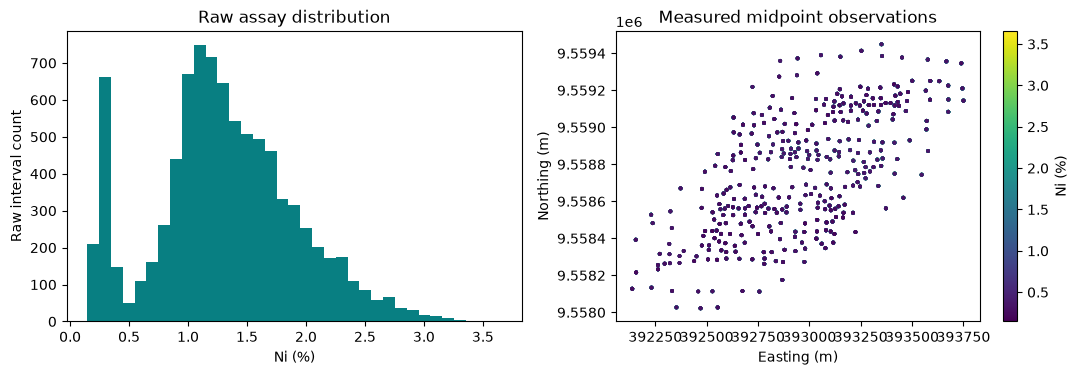

In [4]:
workshop.step_04()

**Cara membaca grafik:** histogram Ni dan peta titik bor. Lihat dulu sebaran data dan nilai kosong sebelum membuat domain.


### Baca polanya, jangan mengejar korelasi tinggi
Tujuh unsur/oksida dalam persen; **SG tidak bersatuan**. Bandingkan histogram dan diagram pencar per litologi. Hubungan Fe–SiO₂ yang berlawanan saat semua litologi dicampur bisa berasal dari lapisan yang berbeda. Korelasi gabungan bukan alasan otomatis untuk membuat domain atau top-cut. Heatmap khusus SAP membantu membedakan pola di dalam satu lapisan dari efek pencampuran. Tidak ada kadar yang diubah supaya grafik terlihat bagus.


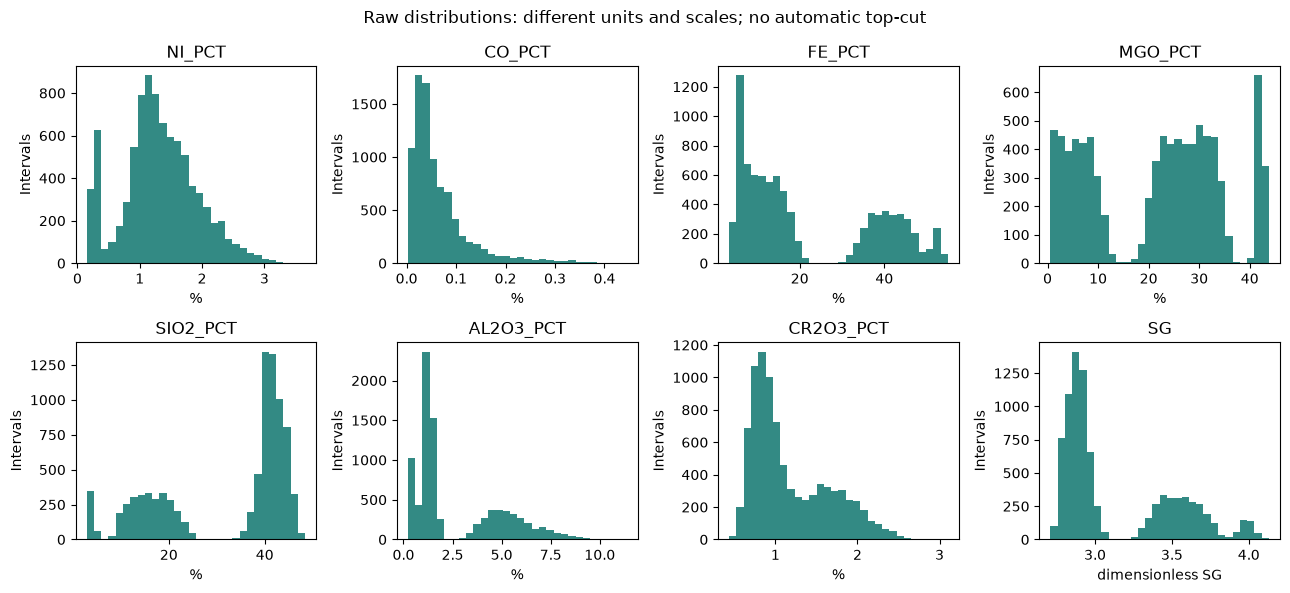

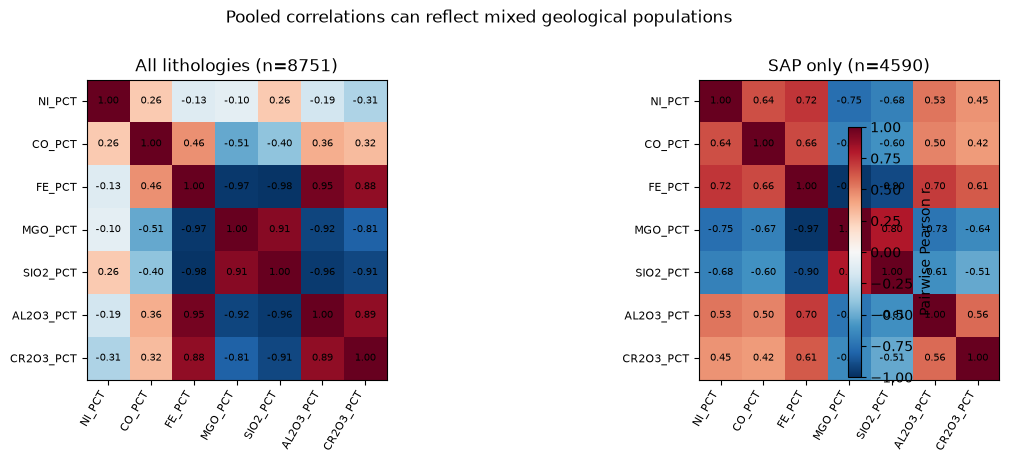

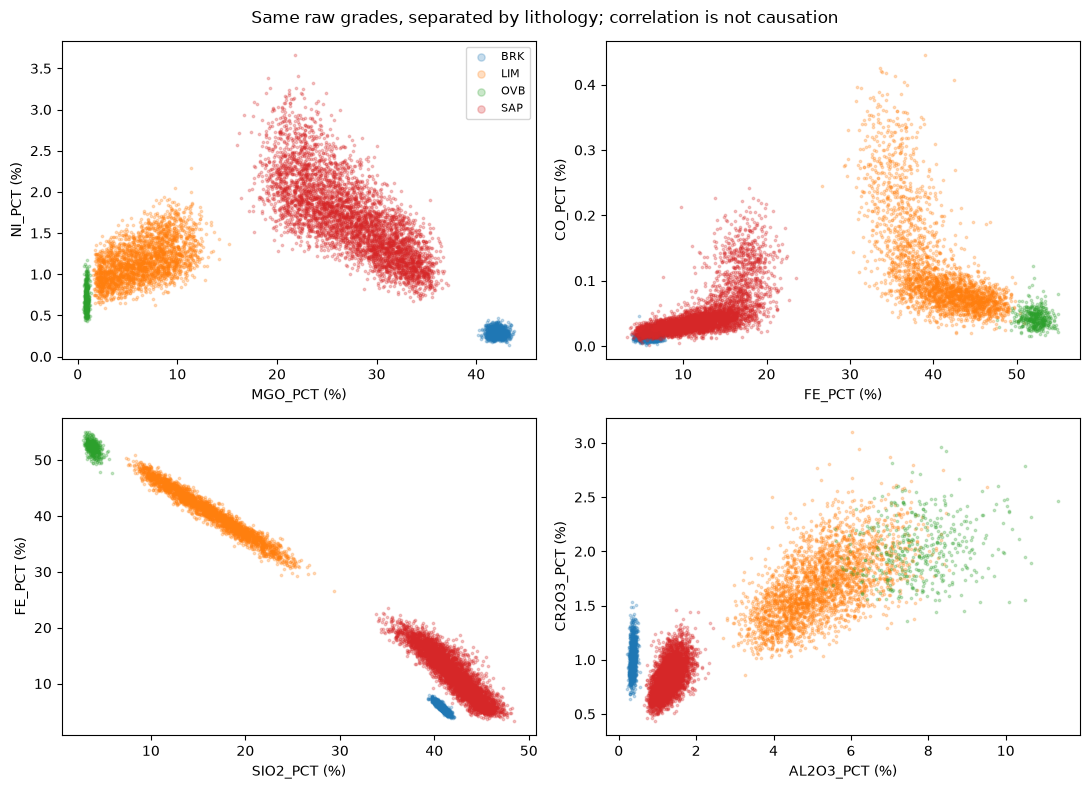

Element grades Ni/Co/Fe are elemental mass percent; MgO/SiO2/Al2O3/Cr2O3 are oxide mass percent. SG is dimensionless, not measured dry bulk density.
Missing values remain missing. Histograms are unweighted interval diagnostics; final resource means use supported tonnes.


In [5]:
workshop.plot_eda()

**Cara membaca grafik:** sebaran delapan variabel. Unsur/oksida dalam persen, SG tanpa satuan. Skalanya berbeda, jadi jangan membandingkan angkanya langsung.


**Cara membaca grafik:** korelasi semua litologi dibanding korelasi SAP saja. Mencampur litologi bisa memperkuat atau membalik hubungan antarunsur.


**Cara membaca grafik:** diagram pencar per litologi. Pola di dalam tiap lapisan lebih berguna daripada korelasi yang terlihat tinggi.


### Apakah setiap kadar masuk akal?
Ni, Co dan Fe dalam persen unsur; MgO, SiO₂, Al₂O₃ dan Cr₂O₃ dalam persen oksida. SG tidak bersatuan. Histogram dan korelasi dipakai untuk memeriksa, bukan sebagai batas kadar yang berlaku umum.

Jumlah semua komponen dalam satu sampel tidak boleh lebih dari 100 %. Dataset versi lama punya 10 sampel yang melanggar ini; versi 4 sudah memperbaikinya di model sintetisnya (penjelasan di `../output/genesis/genesis-method.md`). Pada data lapangan, sampel seperti itu dicek ke laboratorium, bukan dinormalkan otomatis.


## 4 · Surface, domain dan solid adalah hal berbeda
**Surface-pair:** solid SAP dibentuk dari permukaan atas SAP sampai permukaan bawah SAP. Dengan cara yang sama, LIM bisa dibentuk dari atas LIM sampai atas SAP bila log mendukung. **Loft:** garis tertutup digambar pada beberapa section sejajar, lalu disambung menjadi solid.

**Lakukan:** lihat mesh solid yang dibuat di GeoSuite. Solid ini keputusan geologi yang dipakai sebagai input; notebook tidak menyimpulkannya sendiri.

**Cek:** mesh SAP harus sama persis dengan hasil Core (dicek dengan sidik jari file/hash). Volume mesh berbeda dengan volume blok terisi dan dengan tonase. Density 1,6 t/m³ hanya asumsi latihan.

**Contoh SAP berulang:** bila satu lubang punya SAP di 1–4 m dan 6–7 m, celah 4–6 m bukan SAP. Kode di bawah menolak lubang dengan beberapa potongan yang belum diinterpretasi, daripada menganggapnya satu lapisan utuh.


PASS exact SAP vertices/faces hash vs native Core: 0200454b7309a491de9ff24bb7757dc601f9d8305e468fccef979ea883116cb2
Same interpreted body: SAP volume 15304948.715316297 m3
Same interpreted body: LIM volume 9120561.31720057 m3
Interpreted SAP whole-mesh volume (not block volume): 15304948.715316301 m³


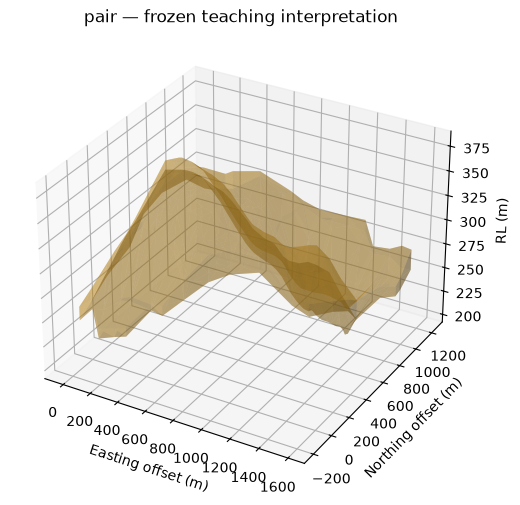

In [6]:
workshop.step_05()

**Cara membaca grafik:** geometri solid yang dipakai sebagai input. Gambar ini tidak membuktikan kemenerusan geologi.


## 5 · Batasi assay dengan solid
**Lakukan:** untuk setiap lubang, cari bagian lubang yang berada di dalam solid. Lubang yang hanya menyentuh tepi solid dilaporkan terpisah, tidak diam-diam dianggap di dalam.

**Cek (Surface-pair):** 302 lubang di dalam dan 38 lubang di tepi; 4.122 m di dalam solid dan 468 m di tepi yang tidak otomatis dimasukkan. Ke-340 lubang tetap disimpan.

**Diskusi:** aturan untuk lubang di tepi solid harus ditetapkan sebelum menghitung tonase.

Tabel berikut menunjukkan sampel di dalam solid: Surface-pair 4.122 sampel tanpa ada yang memotong batas; Loft 250 sampel, 32 di antaranya memotong batas. Rata-rata di tabel belum dibobot panjang. Hasil akhir tetap tanpa top-cut, sama dengan aplikasi.


In [7]:
workshop.step_06()

Interior holes: 302 Boundary holes excluded explicitly: 38
PASS same domain-constrained parent EDA population/support as UI: 4122 parents; 0 crossing
                        scope  rows  Ni_valid  Ni_missing  mean_unweighted_Ni_pct
                    Raw assay  8751      8717          34                1.313883
SAP reviewed geometry parents  4122      4111          11                1.680841
Final active treatment: none. Geometry parent EDA is diagnostic, not per-span grade treatment or an automatic cap decision.


## 6 · Komposit 2 m dengan bobot panjang
Rumus: `kadar = Σ(panjang × kadar) / Σ(panjang yang punya kadar)`. Nilai kosong tidak dihitung sebagai nol. Sisa komposit di ujung lubang (*tail*) tetap ditampilkan. Kadar dihitung dari **assay mentah**, bukan disalin dari komposit GeoSuite.

**Cek:** Surface-pair 2.139 komposit, Loft 124 komposit. Hasil dibandingkan sampai 6 desimal untuk kedalaman dan 10 desimal untuk kadar, lalu ditulis ke `hasil-python/`.

**Latihan:** hitung satu komposit dengan tangan, lalu bandingkan panjang fisiknya dengan panjang yang punya nilai Ni.


In [8]:
workshop.step_07()

Composites: 2139 Physical support: 4122.0 m; missing composite Ni: 1
Max composite grade difference vs GeoSuite export: 3.064215547965432e-14 percentage points


## 7 · Variogram per arah dengan model yang sama seperti di aplikasi
**Lakukan:** hitung variogram arah timur–barat, utara–selatan, vertikal dan omni dengan lag, jarak maksimum dan toleransi yang sama dengan aplikasi. Jarak horizontal memakai X/Y; vertikal memakai selisih Z untuk pasangan yang jarak X/Y-nya paling jauh 5 m. Setiap kelas jarak butuh minimal 5 pasangan, dan satu arah butuh minimal 3 kelas. Karena itu arah utara–selatan pada Loft ditolak, sama seperti di aplikasi.

Jumlah pasangan dan nilai gamma dibandingkan dengan GeoSuite. Model spherical memakai nugget, sill dan range yang persis sama. Saran *Auto fit* hanya titik awal, bukan keputusan geologi.

**Cek:** nugget, sill dan range tercatat. Model variogram memakai jarak sebenarnya; ellipsoid search hanya menentukan sampel tetangga mana yang dipakai. Keduanya parameter yang berbeda.


Applied derived CSV handoff grade precision: ten decimal places; raw grades unchanged
Max geometric round-trip difference (m): 5.684341886080802e-14
EW : PASS 327104 pairs; 10 bins; max gamma difference 0.0
NS : PASS 272981 pairs; 10 bins; max gamma difference 0.0
vert : PASS 7839 pairs; 10 bins; max gamma difference 0.0
omni : PASS 1154035 pairs; 10 bins; max gamma difference 0.0


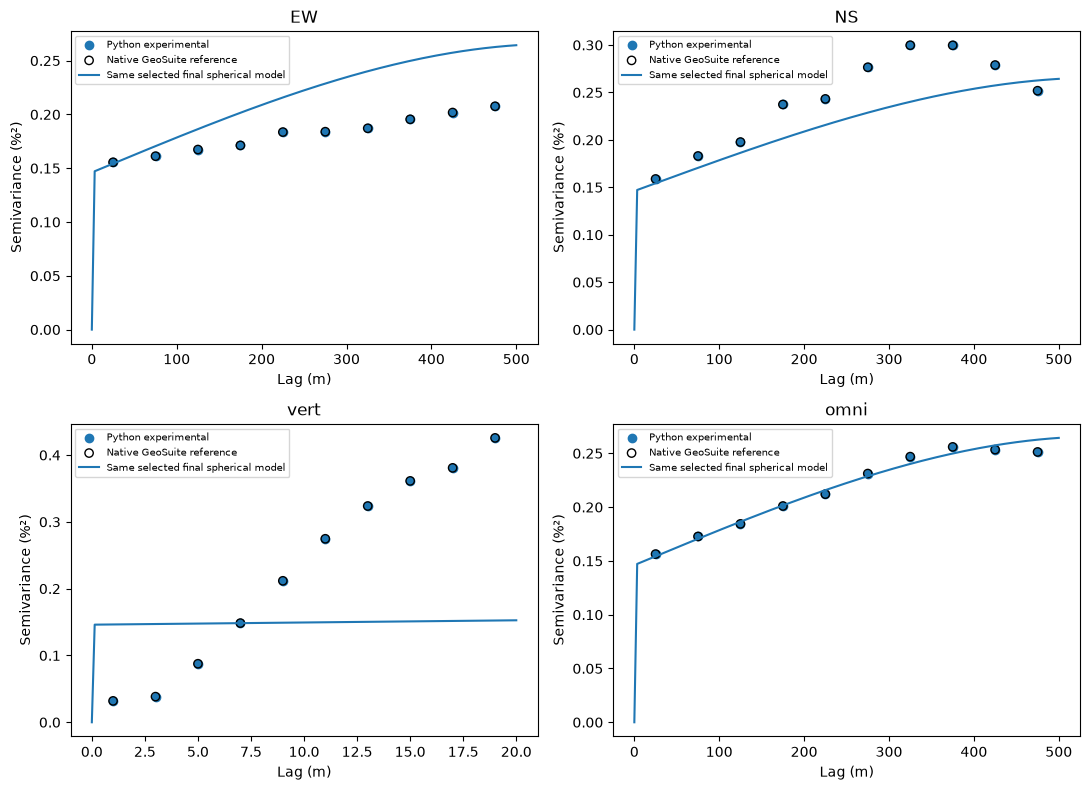

Same selected final model: {'type': 'spherical', 'nugget': 0.1461, 'sill': 0.2656, 'range': 546.3, 'covarianceMode': 'model-range'}


In [9]:
workshop.step_08()

**Cara membaca grafik:** variogram per arah beserta jumlah pasangannya. Kelas jarak dengan pasangan terlalu sedikit tidak dipakai.


## 8 · Volume blok dan estimasi NN/IDW/OK
**Lakukan:** pakai volume blok yang sudah dipotong solid dari GeoSuite. Kadar blok GeoSuite hanya dipakai di sel perbandingan, tidak sebagai input.

Parameter search: 250 / 250 / 50 m, azimuth 0°, dip 0°, minimal 2 dan maksimal 12 tetangga, tanpa octant dan tanpa second pass. NN memakai satu sampel terdekat; IDW memakai jarak pangkat 2; OK menyelesaikan sistem kriging dengan jumlah bobot sama dengan 1.

**Cek:** Surface-pair 2.237 blok terestimasi, Loft 58 blok. Kadar NN/IDW/OK per blok harus sama dengan GeoSuite. Nilai -999 di file ekspor berarti blok tidak diestimasi, bukan kadar negatif.


In [10]:
workshop.step_09()

Estimated supported blocks: 2237
NN PASS exact stored Float32 parity: 2237 blocks
IDW PASS exact stored Float32 parity: 2237 blocks
OK PASS exact stored Float32 parity: 2237 blocks
PASS kriging variance and neighbour counts; maximum variance difference: 5.053186046544145e-07


## 9 · Bandingkan hasilnya dengan angka
**Lakukan:** baca selisih maksimum, RMSE dan bias, lalu lihat diagram pencarnya, bukan hanya angka total.

Batas selisih yang diterima sangat kecil: hanya sebesar pembulatan penyimpanan angka di aplikasi dan pembulatan 6 desimal di file ekspor. Kalau ada cek yang gagal, berhenti dan periksa input atau parameter. Jangan mengubah parameter hanya supaya lulus.

**Batasnya:** geometri dan volume blok berasal dari GeoSuite. Kecocokan di sini membuktikan perhitungannya sama, bukan membuktikan interpretasi geologinya benar.


method  blocks  max_abs_percentage_points  RMSE_percentage_points  bias_percentage_points precision_check                                                tolerance_basis
    NN    2237               0.000000e+00            0.000000e+00            0.000000e+00            PASS Float32 half-ULP + six-decimal export half-unit + solver bound
   IDW    2237               5.810293e-07            2.918971e-07            8.299391e-09            PASS Float32 half-ULP + six-decimal export half-unit + solver bound
    OK    2237               6.085750e-07            2.882833e-07            8.430604e-09            PASS Float32 half-ULP + six-decimal export half-unit + solver bound


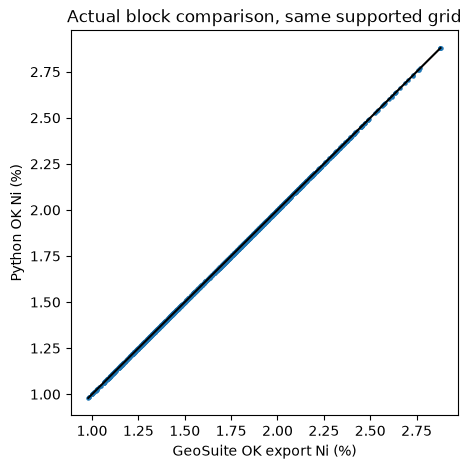

In [11]:
workshop.step_10()

**Cara membaca grafik:** kadar blok GeoSuite dibanding Python dengan input dan parameter yang sama. Titik yang jatuh di garis 1:1 berarti angkanya sama.


## 10 · Cross-validation dengan aturan yang sama
**Lakukan:** setiap komposit dikeluarkan satu per satu lalu diestimasi dari tetangganya (*leave-one-out*). Surface-pair memakai 200 komposit, Loft 124 komposit. Pilihan sampel, tetangga dan aturan jaraknya sama dengan aplikasi, sehingga setiap prediksi bisa dibandingkan. Ini bukan *leave-one-hole-out*. Nilai r² adalah kuadrat korelasi Pearson, sama dengan yang ditampilkan aplikasi.

**Cek:** hasilnya selalu sama bila input dan parameter sama. Setelah mengganti `MODE`, jalankan Run All lagi.

**Kesimpulan yang boleh disampaikan:** perhitungan GeoSuite pada dataset latihan ini sudah dicek ulang dengan Python dan hasilnya sama. Ini bukan review geologi independen dan bukan laporan sumber daya.


method  valid_pairs     RMSE      bias  source_UI_RMSE result
    NN          200 0.271167  0.096635        0.271167   PASS
   IDW          200 0.227473 -0.002859        0.227473   PASS
    OK          200 0.303121  0.006745        0.303121   PASS
CV r² follows UI squared Pearson correlation; this is not 1-SSE/SST and not drillhole-held-out validation.


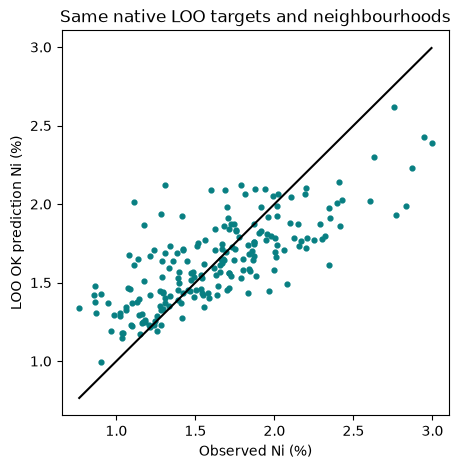

In [12]:
workshop.step_11()

**Cara membaca grafik:** hasil cross-validation. Bandingkan bias, RMSE dan tingkat penghalusan (*smoothing*). Pada data ini IDW memberi RMSE lebih rendah daripada OK.


## 11 · Density, cutoff, grade–tonnage dan laporan
Rumus: `tonase = volume blok terisi × density`; `Ni terkandung = tonase × Ni% / 100`. Kadar rata-rata dibobot tonase.

**Lakukan:** lihat perubahan pada cutoff 0–3 % Ni. Seluruh kurva tonase dan kadar dibandingkan dengan aplikasi, bukan hanya titik akhirnya. Tonase dengan 2 desimal harus sama: Surface-pair 21.298.329,56 t, Loft 689.113,17 t. Bedakan volume solid, volume blok terisi, tonase terestimasi dan volume yang tidak terestimasi.

**Diskusi:** bagaimana kalau density berbeda per litologi? Kenapa kurva ini belum cukup untuk menyatakan prospek ekonomi (RPEEE), klasifikasi atau cadangan?


 cutoff_Ni_pct       tonnes  mean_Ni_pct  contained_Ni_t
           0.0 2.129833e+07     1.700600   362199.366079
           0.5 2.129833e+07     1.700600   362199.366079
           1.0 2.128160e+07     1.701153   362032.611476
           1.5 1.565578e+07     1.830722   286613.776737
           2.0 3.273464e+06     2.188679    71645.621817
           2.5 2.051333e+05     2.634977     5405.217277
           3.0 0.000000e+00          NaN        0.000000
Aggregate reconciliation PASS; mean-grade tolerance: 6.886222283436815e-08 percentage points; contained-metal tolerance: 0.014669767662719817 t
FINAL UI / NOTEBOOK CHECK, SAME DOMAIN / SUPPORT / DENSITY / CUTOFF:
               metric       Python     GeoSuite  absolute_difference    tolerance result
Supported volume (m3) 1.331146e+07 1.331146e+07         1.303852e-08 1.000000e-05   PASS
    Final tonnage (t) 2.129833e+07 2.129833e+07         3.352761e-08 1.000000e-04   PASS
          Mean Ni (%) 1.700600e+00 1.700600e+00         3.330669

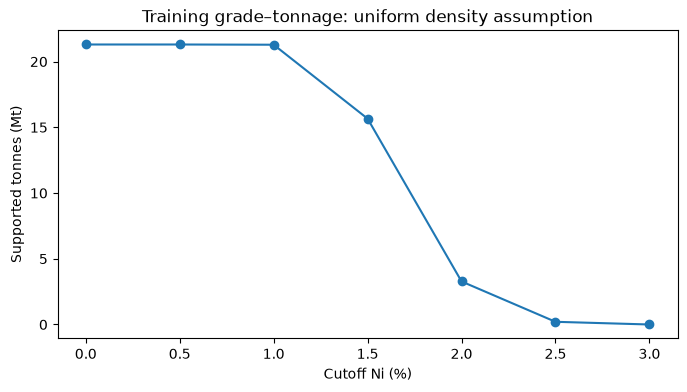

{
  "mode": "pair",
  "raw_counts": {
    "collar": 340,
    "survey": 680,
    "assay": 8751,
    "litho": 1344
  },
  "mesh_sha256": "0200454b7309a491de9ff24bb7757dc601f9d8305e468fccef979ea883116cb2",
  "native_UI_source": "e7f79300ef474795a138f9226eec494e58abf903",
  "cv_UI_source": "60e44e7a25f9ab8eb6b2857fcb04d26a59259bcb",
  "mesh_volume_m3": 15304948.715316301,
  "composites": 2139,
  "composite_physical_support_m": 4122.0,
  "estimated_blocks": 2237,
  "supported_volume_m3": 13311455.976011543,
  "tonnes": 21298329.56161847,
  "comparison": [
    {
      "method": "NN",
      "blocks": 2237,
      "max_abs_percentage_points": 0.0,
      "RMSE_percentage_points": 0.0,
      "bias_percentage_points": 0.0,
      "precision_check": "PASS",
      "tolerance_basis": "Float32 half-ULP + six-decimal export half-unit + solver bound"
    },
    {
      "method": "IDW",
      "blocks": 2237,
      "max_abs_percentage_points": 5.810292695862529e-07,
      "RMSE_percentage_points": 2.918970

In [13]:
workshop.step_12()

**Cara membaca grafik:** kurva grade–tonnage dari kadar dan volume blok yang sama. Cutoff hanya memilih blok mana yang dilaporkan; kadar bloknya tidak berubah.


### Menjelaskan angka akhir
Bandingkan tingkat penghalusan NN, IDW dan OK pada blok yang sama. Tonase = **volume blok terisi × density kering 1,6 t/m³**; Ni terkandung = tonase × Ni / 100. Menaikkan cutoff menaikkan kadar rata-rata dan mengurangi tonase. Grafik ini belum menentukan prospek ekonomi, klasifikasi sumber daya atau keputusan Competent Person.


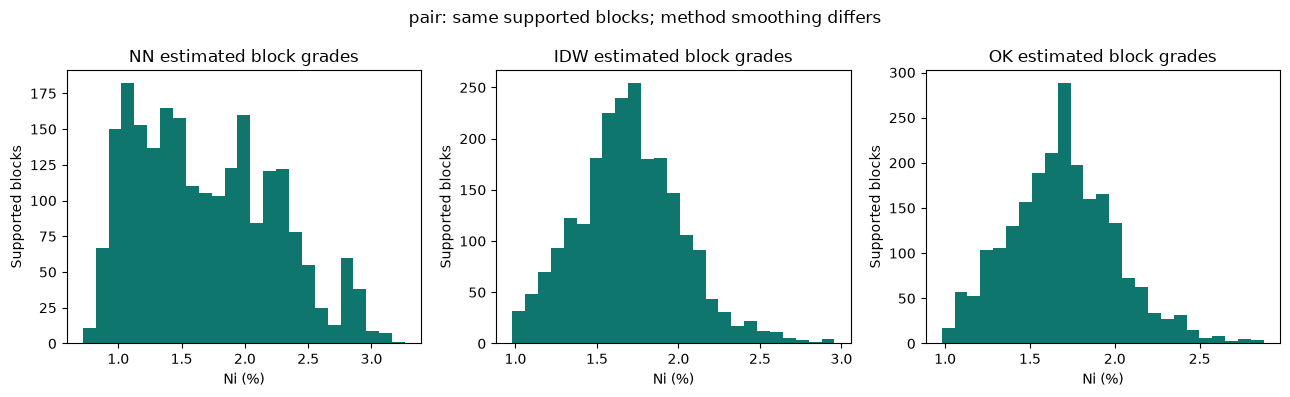

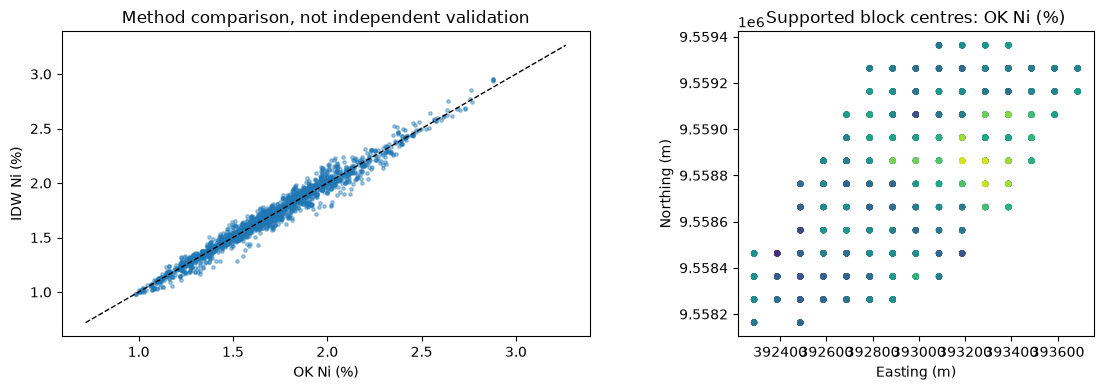

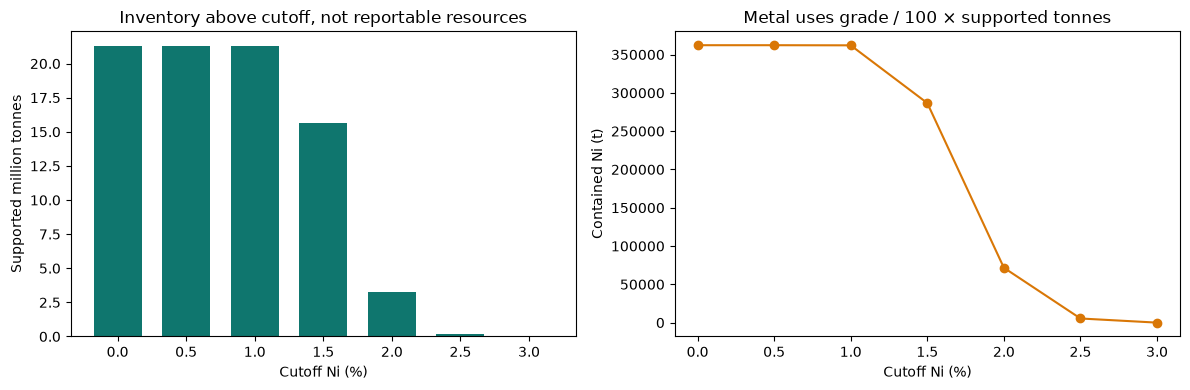

Tonnage: sum of clipped support volume × explicit educational dry density 1.6 t/m³. Do not substitute the SG column.
Pair and loft are different interpretations. Shared mesh/support fixes the comparison scope; CP/geological acceptance remains separate.


In [14]:
workshop.plot_resource()

**Cara membaca grafik:** sebaran kadar blok NN, IDW dan OK. Ketiganya dari endapan yang sama; bedanya hanya tingkat penghalusan.


**Cara membaca grafik:** peta blok tiap metode. Peta ini tidak membuat interpretasi geologi baru.


**Cara membaca grafik:** rekonsiliasi tonase dan Ni terkandung. Density 1,6 t/m³ adalah asumsi latihan, terpisah dari kolom SG.


## Referensi dan latihan lanjutan
- Data: Orebit Synthetic Drillhole Datasets, nikel laterit, 340 lubang, CC BY 4.0.
- Parameter dan geometri: `../output/parameters.json`, `interpreted-solid.json` dan `geometry-full-precision.json`.
- CIM (2019) Best Practice: EDA §6.2, komposit §6.4, density §6.5, kemenerusan §6.8, validasi model §6.10.
- JORC (2012) Table 1 Section 3 dan SNI 4726:2019 mengatur pelaporan; tonase dari notebook ini tidak otomatis memenuhinya.
- Daftar lengkap: [Daftar referensi](../Daftar_Referensi.html).
- Menemukan error? Catat MODE, sel yang gagal dan pesan errornya.

**Latihan mandiri:** jelaskan pilihan geologi Anda, volume yang tidak ikut dihitung, pengaruh panjang komposit, pilihan model dan search, dan kenapa tonase Surface-pair tidak boleh dibandingkan langsung dengan Loft.
